# Milestone 1 – Text → Embedding Baseline
Caption → CLIP tokens (padded/truncated to 77) → per-token hidden states + pooled vector,
using the text encoder from the **same Stable Diffusion checkpoint** the U-Net will use.

**Input:** `manifest.csv` from `01_data_prep` (columns: `image_id`, `file_path`, `caption`).
**Output:** `embeddings/text_embeddings_sd21_caption.pt`, `token_stats_sd21_caption.csv`, `embedding_config_sd21_caption.json`.



## 1. Setup: install libraries and pin versions

In [ ]:
from pathlib import Path
from importlib.metadata import version

try:
    from google.colab import drive
    drive.mount('/content/drive')
    ROOT = Path("/content/drive/MyDrive/IE7615_Project2")
except ImportError:
    ROOT = Path("./IE7615_Project2")

REQ = Path(ROOT / "requirements.txt")

if REQ.exists():
    !pip -q install -r "{REQ}"
else:
    !pip -q install diffusers transformers accelerate
    pins = {p: version(p).split("+")[0] for p in ["torch", "diffusers", "transformers", "accelerate"]}
    REQ.write_text("".join(f"{p}=={v}\n" for p, v in pins.items()))

print(REQ.read_text())


Mounted at /content/drive
torch==2.11.0
diffusers==0.42.1
transformers==5.22.0
accelerate==1.15.0



In [ ]:
import json, random
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
from transformers import CLIPTokenizer, CLIPTextModel

### 1.1 Config for reproducibility

In [ ]:
SEED          = 42
CKPT          = "sd2-community/stable-diffusion-2-1-base"
REVISION      = "4e63672c03103b6c636b8fb4119ba982469b2955" # filled in during Step 3, then kept fixed
MODEL_TAG     = "sd21"        # For SD 2.1 change to "sd21" | For SD 1.5 change to "sd15"
CAPTION_COL   = "caption"     # "caption_longest" for the side experiment
MANIFEST_NAME = "manifest.csv"
BATCH         = 64
OVERWRITE     = False         # set to True if you want to replace the existing embedding file, otherwise leave as False
STEPS         = 30
GUIDANCE      = 7.5
DATA    = ROOT / "data"
EMB_DIR = ROOT / "embeddings"
RESULTS = ROOT / "results" / "milestone1"
for d in (EMB_DIR, RESULTS): d.mkdir(parents=True, exist_ok=True)

RUN_TAG = f"{MODEL_TAG}_{CAPTION_COL}"
print("RUN_TAG:", RUN_TAG)

RUN_TAG: sd21_caption


### 1.2 Pinning the checkpoint revision

In [ ]:
from huggingface_hub import HfApi
latest = HfApi().model_info(CKPT).sha

if REVISION is None:
    REVISION = latest
    print(f"Paste into config: REVISION = '{REVISION}'")
elif REVISION != latest:
    print(f"Repo has new commits since pinning; still using {REVISION[:10]}")

## 2. Environment: Drive, GPU, paths, seed

In [ ]:
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)

device = "cuda" if torch.cuda.is_available() else "cpu"
print("device:", device, "|", torch.cuda.get_device_name(0) if device == "cuda" else "NO GPU")

device: cuda | Tesla T4


## 3. Load the manifest

In [ ]:
manifest = pd.read_csv(DATA / MANIFEST_NAME)
assert CAPTION_COL in manifest.columns, f"{CAPTION_COL} not in {list(manifest.columns)}"
assert manifest["image_id"].is_unique
captions = manifest[CAPTION_COL].tolist()
print(manifest.shape)
manifest.head(3)


(2000, 3)


,image_id,file_path,caption
0,139,processed_512/000000000139.png,A woman stands in the dining area at the table.
1,285,processed_512/000000000285.png,A big burly grizzly bear is show with grass in...
2,632,processed_512/000000000632.png,"Bedroom scene with a bookcase, blue comforter ..."


## 4. Load CLIP tokenizer and text encoder from the SD checkpoint

In [ ]:
tokenizer = CLIPTokenizer.from_pretrained(CKPT, subfolder="tokenizer", revision=REVISION)
text_encoder = CLIPTextModel.from_pretrained(
    CKPT, subfolder="text_encoder", dtype=torch.float16, revision=REVISION,
).to(device).eval()

HIDDEN = text_encoder.config.hidden_size
print("hidden size:", HIDDEN, "| layers:", text_encoder.config.num_hidden_layers)
print("pad token:", tokenizer.pad_token, tokenizer.pad_token_id,
      "| pad == EOS:", tokenizer.pad_token_id == tokenizer.eos_token_id)

MAX_LEN = tokenizer.model_max_length
print("max length:", MAX_LEN)
print("BOS:", tokenizer.bos_token_id, "| EOS:", tokenizer.eos_token_id, "| PAD:", tokenizer.pad_token_id)




tokenizer_config.json:   0%|          | 0.00/807 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/1.06M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/525k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/460 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/613 [00:00<?, ?B/s]

text_encoder/model.safetensors: reconstructing file:   0%|          |  0.00B / 1.36GB            

text_encoder/model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/372 [00:00<?, ?it/s]

hidden size: 1024 | layers: 23
pad token: ! 0 | pad == EOS: False
max length: 77
BOS: 49406 | EOS: 49407 | PAD: 0


## 5. Tokenization of one caption

In [ ]:
cap = captions[0]
enc = tokenizer(cap, padding="max_length", max_length=MAX_LEN, truncation=True, return_tensors="pt")
ids = enc.input_ids[0].tolist()

print("caption:", cap)
print("input_ids shape:", tuple(enc.input_ids.shape))
n_real = ids.index(tokenizer.eos_token_id) + 1
print("real tokens (incl. BOS+EOS):", n_real, "| padding tokens:", MAX_LEN - n_real)
print(tokenizer.convert_ids_to_tokens(ids[:n_real]))


caption: A woman stands in the dining area at the table.
input_ids shape: (1, 77)
real tokens (incl. BOS+EOS): 13 | padding tokens: 64
['<|startoftext|>', 'a</w>', 'woman</w>', 'stands</w>', 'in</w>', 'the</w>', 'dining</w>', 'area</w>', 'at</w>', 'the</w>', 'table</w>', '.</w>', '<|endoftext|>']


## 6. Embedding function and output shapes

In [ ]:
# the core pipeline: captions -> tokens (padded/truncated to 77) -> embeddings.
@torch.no_grad()
def embed(texts):
    tok = tokenizer(texts, padding="max_length", max_length=MAX_LEN,
                    truncation=True, return_tensors="pt")
    out = text_encoder(tok.input_ids.to(device))
    return tok.input_ids, out.last_hidden_state, out.pooler_output

ids_b, hidden, pooled = embed(captions[:4])
print("input_ids         :", tuple(ids_b.shape))
print("last_hidden_state :", tuple(hidden.shape), hidden.dtype)
print("pooler_output     :", tuple(pooled.shape), pooled.dtype)


input_ids         : (4, 77)
last_hidden_state : (4, 77, 1024) torch.float16
pooler_output     : (4, 1024) torch.float16


**What the shapes mean**
- `last_hidden_state` `[B, 77, HIDDEN]`: one contextual vector per token position. This is what the U-Net's cross-attention layers use as keys and values, so it is the conditioning that matters for Stable Diffusion.
- `pooler_output` `[B, HIDDEN]`: the hidden state at the end-of-text token, after the final layer norm. It is a single summary vector per caption. SD 1.x does not use it, but it is handy for comparing captions.
- Positions after the end-of-text token are padding (for SD1.5, the pad token is the end-of-text token). SD does not mask them.

In [ ]:
# confirm pooled == hidden state at the first EOS position
# argmax over ids finds the first EOS because 49407 is the largest id in the vocab.
eos_pos = ids_b.argmax(dim=-1)
manual = hidden[torch.arange(hidden.size(0)), eos_pos.to(device)]
print("EOS positions:", eos_pos.tolist())
print("pooled == hidden@EOS:", torch.allclose(pooled, manual, atol=1e-3))


EOS positions: [12, 15, 14, 11]
pooled == hidden@EOS: True


## 7. Sanity check: cosine similarity

This checks the pooled vector for semantic sense. The U-Net uses the per-token hidden states, which get validated end to end in Milestone 2. For SD 2.1, the pooled vector comes from the second-to-last layer without CLIP's projection, so its similarity values are a weaker signal than SD 1.5's.

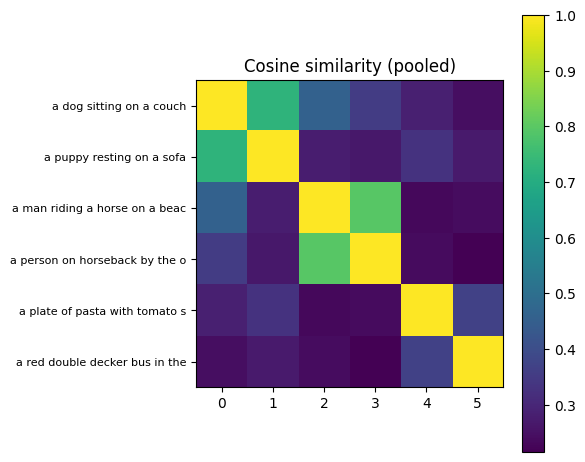

paraphrase A (0,1): 0.725
paraphrase B (2,3): 0.796
unrelated   (0,4): 0.284 | (2,5): 0.240 | (4,5): 0.368


In [ ]:
#test on random captions
import torch.nn.functional as F

test = [
    "a dog sitting on a couch",              # 0 \ paraphrase pair A
    "a puppy resting on a sofa",             # 1 /
    "a man riding a horse on a beach",       # 2 \ paraphrase pair B
    "a person on horseback by the ocean",    # 3 /
    "a plate of pasta with tomato sauce",    # 4 unrelated
    "a red double decker bus in the city",   # 5 unrelated
]
_, _, p = embed(test)
p = F.normalize(p.float(), dim=-1)
sim = (p @ p.T).cpu().numpy()

fig, ax = plt.subplots(figsize=(6, 5))
im = ax.imshow(sim, vmin=sim.min(), vmax=1.0, cmap="viridis")
ax.set_xticks(range(len(test))); ax.set_yticks(range(len(test)))
ax.set_xticklabels(range(len(test))); ax.set_yticklabels([t[:30] for t in test], fontsize=8)
plt.colorbar(im); plt.title("Cosine similarity (pooled)"); plt.tight_layout(); plt.show()

print(f"paraphrase A (0,1): {sim[0,1]:.3f}")
print(f"paraphrase B (2,3): {sim[2,3]:.3f}")
print(f"unrelated   (0,4): {sim[0,4]:.3f} | (2,5): {sim[2,5]:.3f} | (4,5): {sim[4,5]:.3f}")


In [ ]:
probe = captions[:200]
_, _, p = embed(probe)
pn = F.normalize(p.float(), dim=-1)

def nearest(i, k=3):
    s = (pn[i] @ pn.T).cpu().numpy()
    print("query:", probe[i])
    for j in s.argsort()[::-1][1:k + 1]:
        print(f"  {s[j]:.3f}  {probe[j]}")

for i in (0, 1, 13):
    nearest(i)

query: A woman stands in the dining area at the table.
  0.701  A girl with some food and drink at a table.
  0.643  an old woman is in front of some food on a table
  0.573  Smiling lady standing by two bunches of bananas on a table.
query: A big burly grizzly bear is show with grass in the background.
  0.531  A sheep standing in grass next to a rock wall.
  0.496  A zebra in the grass who is cleaning himself.
  0.491  A herd of elephants standing on top of a field.
query: A large white bowl of many green apples.
  0.640  A bowl filled with lots of oranges on a counter.
  0.581  A collection of apples growing on a tree.
  0.467  A bunch of bananas sitting on top of a wooden table.


## 8. Truncation count and token lengths

Truncated captions: 0 / 2000
count    2000.00000
mean       13.50250
std         2.43474
min         9.00000
25%        12.00000
50%        13.00000
75%        15.00000
max        30.00000
Name: n_tokens, dtype: float64


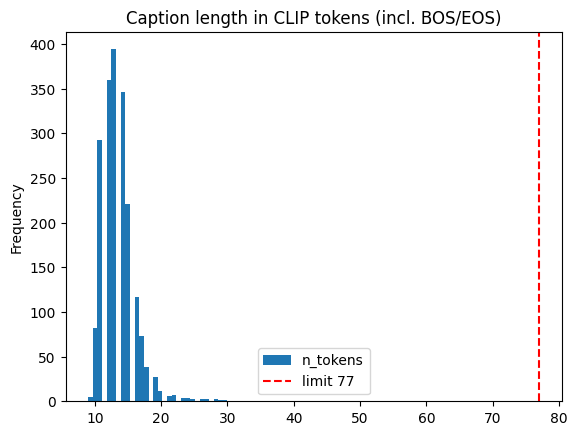

In [ ]:
lens = [len(x) for x in tokenizer(captions, truncation=False)["input_ids"]]
manifest["n_tokens"] = lens
manifest["truncated"] = manifest["n_tokens"] > MAX_LEN

print(f"Truncated captions: {manifest['truncated'].sum()} / {len(manifest)}")
print(manifest["n_tokens"].describe())

manifest["n_tokens"].plot.hist(bins=30, title="Caption length in CLIP tokens (incl. BOS/EOS)")
plt.axvline(MAX_LEN, color="red", ls="--", label="limit 77"); plt.legend(); plt.show()


## 9. Embed all captions

In [ ]:
from tqdm.auto import tqdm

hid_list, pool_list = [], []
for i in tqdm(range(0, len(captions), BATCH)):
    _, h, p = embed(captions[i:i+BATCH])
    hid_list.append(h.cpu()); pool_list.append(p.cpu())

hidden_all = torch.cat(hid_list)    # [2000, 77, HIDDEN] , HIDDEN = 768 for SD 1.5 | HIDDEN = 1024 for SD 2.1
pooled_all = torch.cat(pool_list)   # [2000, HIDDEN]

uncond = embed([""])[1].cpu()       # [1, 77, HIDDEN]

print(hidden_all.shape, pooled_all.shape, uncond.shape)
print("NaNs:", torch.isnan(hidden_all).any().item())


  0%|          | 0/32 [00:00<?, ?it/s]

torch.Size([2000, 77, 1024]) torch.Size([2000, 1024]) torch.Size([1, 77, 1024])
NaNs: False


## 10. Save and verify

In [ ]:
#save embeddings aligned by image_id, then reload to prove they round-trip.
OUT = EMB_DIR; OUT.mkdir(exist_ok=True)
EMB = OUT / f"text_embeddings_{RUN_TAG}.pt"
if EMB.exists() and not OVERWRITE:
    print(f"{EMB.name} exists and OVERWRITE=False: skipping save, checking it instead")
else:
    torch.save({"image_ids": manifest["image_id"].tolist(), "hidden": hidden_all,
                "pooled": pooled_all, "uncond_hidden": uncond,
                "checkpoint": CKPT, "revision": REVISION, "caption_col": CAPTION_COL}, EMB)

    manifest[["image_id", "n_tokens", "truncated"]].to_csv(RESULTS / f"token_stats_{RUN_TAG}.csv", index=False)

    with open(RESULTS / f"embedding_config_{RUN_TAG}.json", "w") as f:
        json.dump({"checkpoint": CKPT, "revision": REVISION, "model_tag": MODEL_TAG,
               "manifest": MANIFEST_NAME, "caption_col": CAPTION_COL,
               "n_captions": len(manifest), "hidden_size": HIDDEN, "max_len": MAX_LEN,
               "pad_token_id": tokenizer.pad_token_id,
               "n_truncated": int(manifest["truncated"].sum()),
               "max_tokens": int(manifest["n_tokens"].max()),
               "median_tokens": float(manifest["n_tokens"].median()),
               "libraries": REQ.read_text().split()}, f, indent=2)
    print(f"saved {EMB.name}")

chk = torch.load(EMB)
assert chk["hidden"].shape == (len(manifest), MAX_LEN, HIDDEN)
assert chk["image_ids"] == manifest["image_id"].tolist()
assert chk["revision"] == REVISION, "saved file came from a different revision"
print("matches this run:", torch.allclose(chk["hidden"].float(), hidden_all.float(), atol=1e-3))
print("files:", sorted(p.name for p in OUT.iterdir()))

text_embeddings_sd21_caption.pt exists and OVERWRITE=False: skipping save, checking it instead
matches this run: True
files: ['embedding_config_sd15_caption.json', 'embedding_config_sd21_caption.json', 'text_embeddings_sd15_caption.pt', 'text_embeddings_sd21_caption.pt', 'token_stats_sd15_caption.csv', 'token_stats_sd21_caption.csv']


In [ ]:
from diffusers import StableDiffusionPipeline
SAMPLES = RESULTS

pipe = StableDiffusionPipeline.from_pretrained(
    CKPT, revision=REVISION, dtype=torch.float16
).to(device)

emb = torch.load(OUT / f"text_embeddings_{RUN_TAG}.pt")

def gen(**kw):
    g = torch.Generator(device).manual_seed(SEED)
    return pipe(num_inference_steps=STEPS, guidance_scale=GUIDANCE, generator=g, **kw).images[0]

model_index.json:   0%|          | 0.00/543 [00:00<?, ?B/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 13 files:   0%|          | 0/13 [00:00<?, ?it/s]

Loading pipeline components...:   0%|          | 0/6 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/372 [00:00<?, ?it/s]

End-to-end pipeline test:

In [ ]:
i = 0
prompt = captions[i]
img_text = gen(prompt=prompt)
img_emb  = gen(prompt_embeds=emb["hidden"][i:i+1].to(device),
               negative_prompt_embeds=emb["uncond_hidden"].to(device))

  0%|          | 0/30 [00:00<?, ?it/s]

  0%|          | 0/30 [00:00<?, ?it/s]

In [ ]:
diff = np.abs(np.asarray(img_text, dtype=int) - np.asarray(img_emb, dtype=int))
print("max pixel diff:", diff.max())
print("mean diff:", diff.mean().round(3))
print("% pixels differing by >10:", ((diff.max(axis=-1) > 10).mean() * 100).round(2))

max pixel diff: 177
mean diff: 1.962
% pixels differing by >10: 4.66


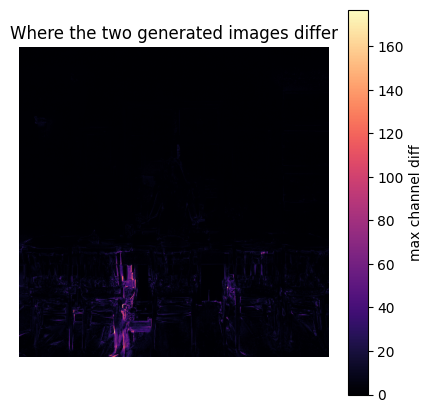

In [ ]:
plt.figure(figsize=(5, 5))
plt.imshow(diff.max(axis=-1), cmap="magma")
plt.colorbar(label="max channel diff"); plt.axis("off")
plt.title("Where the two generated images differ")
plt.savefig(SAMPLES / f"e2e_diffmap_{RUN_TAG}.png", dpi=120, bbox_inches="tight")
plt.show()

Embedding difference check to compare live and saved embeddings:

In [ ]:
with torch.no_grad():
    tok = pipe.tokenizer(prompt, padding="max_length", max_length=77,
                         truncation=True, return_tensors="pt")
    live = pipe.text_encoder(tok.input_ids.to(device))[0]

saved = emb["hidden"][i:i+1].to(device)
print("max embedding diff:", (live - saved).abs().max().item())
print("largest |value| in saved:", saved.abs().max().item())
print("mean embedding diff:", (live - saved).abs().float().mean().item())

max embedding diff: 0.0234375
largest |value| in saved: 13.0234375
mean embedding diff: 0.0018442029831930995


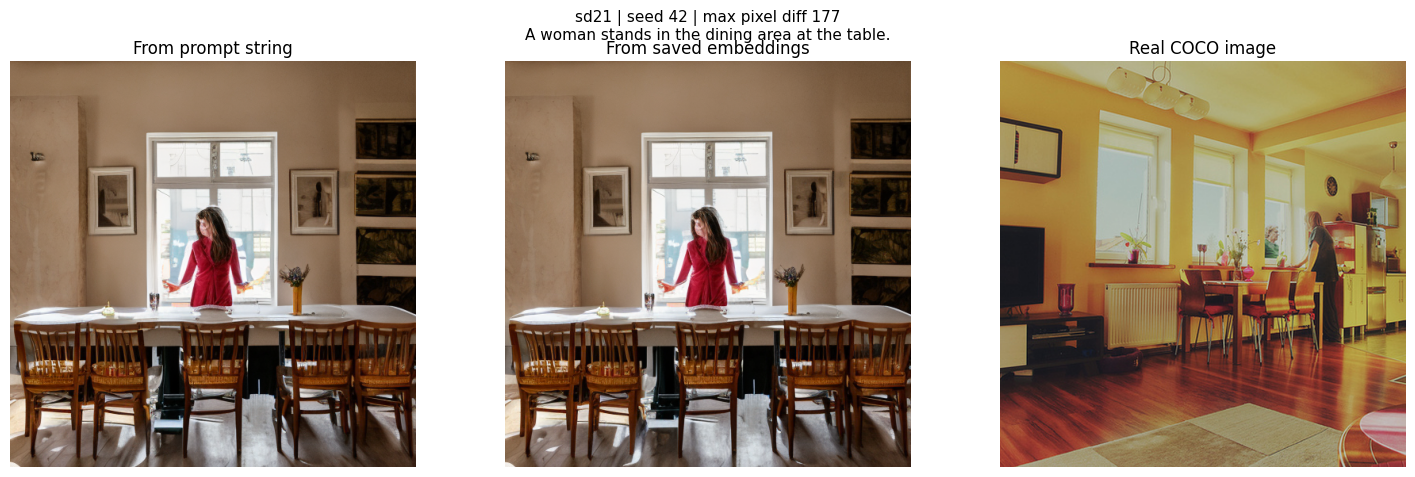

In [ ]:
from PIL import Image
import textwrap

real_path = DATA / manifest.loc[i, "file_path"]
img_real = Image.open(real_path)

panels = [(img_text, "From prompt string"),
          (img_emb,  "From saved embeddings"),
          (img_real, "Real COCO image")]

fig, axes = plt.subplots(1, 3, figsize=(15, 5.5))
for ax, (img, title) in zip(axes, panels):
    ax.imshow(img)
    ax.set_title(title)
    ax.axis("off")

fig.suptitle(f"{MODEL_TAG} | seed {SEED} | max pixel diff {diff.max()}\n"
             + "\n".join(textwrap.wrap(prompt, 90)), fontsize=11)
plt.tight_layout(rect=[0, 0.12, 1, 1])
plt.show()

**Interpreting the end-to-end pipeline test:**

- **Embeddings match within fp16 rounding.** Max difference 0.0234 on a largest value of 13.02 is three
  fp16 rounding steps (spacing 0.0078 at that magnitude), a 0.2% relative error; the mean difference
  is 0.0018. The cause is batch size: saved embeddings were encoded in batches of 64, while the
  pipeline encodes one caption at a time, so GPU kernels round differently.
- **Images are visually identical, not pixel-identical.** Composition, objects and colours match; mean
  pixel difference is 1.96/255, with 4.66% of pixels differing by more than 10 (max 177).
- **Heatmap: differences are concentrated in fine, high-contrast detail in the lower half**:
  (chair spindles, table legs, floor texture); smooth regions such as the wall, window and the
  figure are near zero. The max of 177 is an edge on a chair leg shifting by a pixel or two. You can compare the regions lit up in the heatmap to the region in between the 2nd and 3rd chairs on the generated images (from prompt string vs from saved embeddings) above. Notice how the lighting on the outside leg of the 2nd chair (4th leg from left) and the surrounding region varies slightly in color (pixel value) between the two images.
- **Takeaway.** Over 30 denoising steps, sub-1% differences in conditioning grow into visible
  changes in fine detail but not in content. Model and setting comparisons therefore use the same
  generation path and batch size throughout, and are judged on metrics across many images (FID,
  CLIP score), not on individual pixels.

## 11. Sampling 5 prompts

To pick test prompts without scrolling the manifest (`manifest.csv`), we searched captions for keywords that
signal known difficulty types: counts ("two", "three") and spatial relations ("left", "right",
"on top of", "next to"). The search also showed that COCO rarely describes layout: only 4 of
2,000 captions contain " right ", and all 4 " left " hits use "left" to mean "left behind",
not direction.

In [ ]:
for word in ["two ", "three ", " left ", " right ", " on top of ", " next to "]:
    hits = manifest[manifest[CAPTION_COL].str.contains(word, case=False)]
    print(f"{word!r}: {len(hits)}")
    print(hits[["image_id", CAPTION_COL]].head(3).to_string(index=False), "\n")

'two ': 135
 image_id                                                    caption
     1761                Two planes flying in the sky over a bridge.
     5193 Man and boys holding two surfboards getting picture taken.
     7281            Two men smile as they ride horses on the beach. 

'three ': 29
 image_id                                                caption
    31269                    three zebras in a field near bushes
    90208                   The picture of three buses on a lot.
    97924 Three people are loading a horse into a horse trailer. 

' left ': 4
 image_id                                                   caption
    78266 Kitchen utensils and appliances have been left unattended
   189451                           A piece of cake left on a plate
   439426 A left hand holding a glazed doughnut over a tiled floor. 

' right ': 4
 image_id                                                                                                                              c

From the hits above, we selected 5 IDs, mapped them to their captions (see below) so we could use them to generate our sample images:

In [ ]:
TEST_IDS = [1761, 97924, 25181, 3661, 5600]   # five image_ids, from the image_id column in Sheets

rows = [manifest.index[manifest["image_id"] == iid][0] for iid in TEST_IDS]
for r, iid in zip(rows, TEST_IDS):
    assert emb["image_ids"][r] == iid        # embeddings line up with this row
    print(r, iid, captions[r])

results = []
for r, iid in zip(rows, TEST_IDS):
    img = gen(prompt_embeds=emb["hidden"][r:r+1].to(device),
              negative_prompt_embeds=emb["uncond_hidden"].to(device))
    results.append({"image_id": iid, "caption": captions[r],
                    "generated": img,
                    "real": Image.open(DATA / manifest.loc[r, "file_path"])})
    img.save(SAMPLES / f"sample_{RUN_TAG}_{iid}.png")

10 1761 Two planes flying in the sky over a bridge.
343 97924 Three people are loading a horse into a horse trailer.
114 25181 A train station with an awning is depicted with a train on the right platform.
21 3661 A bunch of bananas sitting on top of a wooden table.
33 5600 A pan filled with onions sitting next to a pan of stew.


  0%|          | 0/30 [00:00<?, ?it/s]

  0%|          | 0/30 [00:00<?, ?it/s]

  0%|          | 0/30 [00:00<?, ?it/s]

  0%|          | 0/30 [00:00<?, ?it/s]

  0%|          | 0/30 [00:00<?, ?it/s]

Results of the generated images based on the selected captions along with their real COCO images:

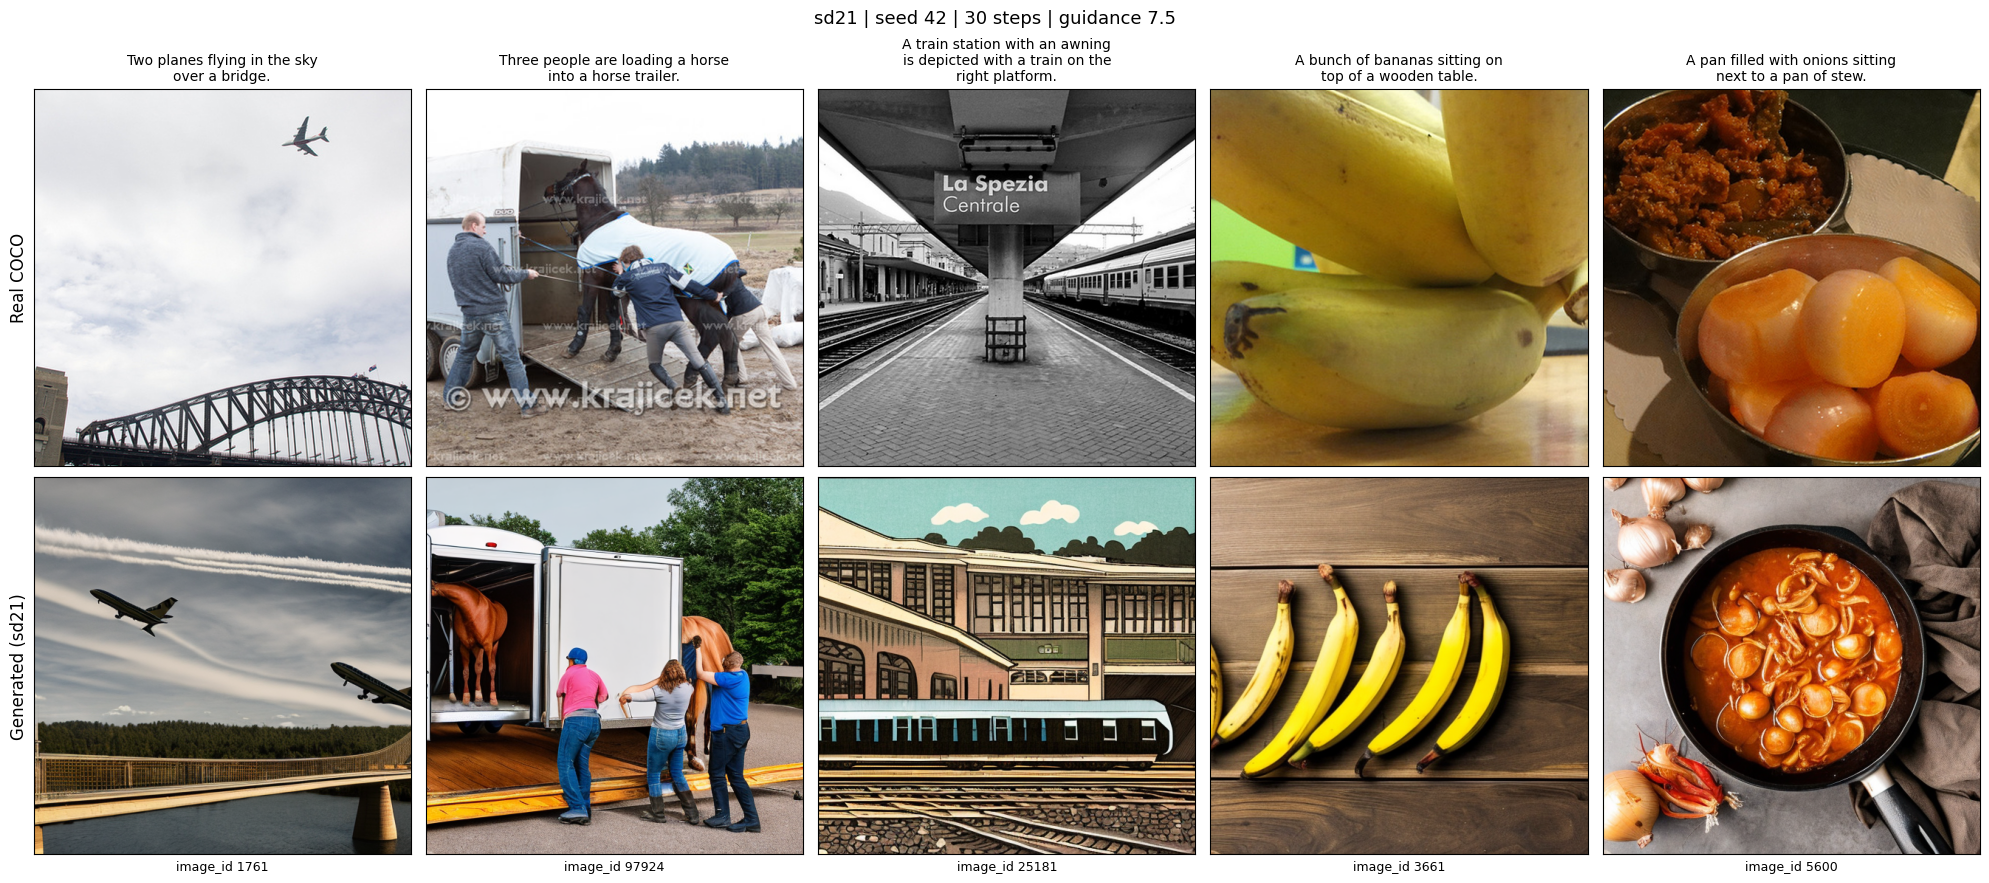

In [ ]:
fig, axes = plt.subplots(2, 5, figsize=(20, 9))

for col, res in enumerate(results):
    axes[0, col].imshow(res["real"])
    axes[0, col].set_title("\n".join(textwrap.wrap(res["caption"], 32)), fontsize=10)
    axes[1, col].imshow(res["generated"])
    axes[1, col].set_xlabel(f"image_id {res['image_id']}", fontsize=9)

for ax in axes.flat:
    ax.set_xticks([]); ax.set_yticks([])     # hide ticks but keep the labels visible

axes[0, 0].set_ylabel("Real COCO", fontsize=12)
axes[1, 0].set_ylabel(f"Generated ({MODEL_TAG})", fontsize=12)

fig.suptitle(f"{MODEL_TAG} | seed {SEED} | {STEPS} steps | guidance {GUIDANCE}", fontsize=13)
plt.tight_layout()
fig.savefig(SAMPLES / f"grid_{RUN_TAG}.png", dpi=120, bbox_inches="tight")
plt.show()

## Summary (SD 2.1)
- **Checkpoint:** `sd2-community/stable-diffusion-2-1-base` @ `4e63672c03`, a community mirror; the official Stability repo has been removed
- **Text encoder:** OpenCLIP ViT-H, 23 layers (second-to-last layer of the original), hidden size 1024
- **Tokenizer:** same CLIP BPE as SD 1.5 (identical token counts); padding uses `!` (ID 0) instead of end-of-text
- **Shapes:** tokens `[B, 77]` → hidden states `[B, 77, 1024]`, pooled `[B, 1024]`; pooled == hidden at end-of-text
- **Truncation:** 0 / 2000; tokens mean 13.5, median 13, max 30
- **Sanity check (pooled):** paraphrases 0.725 / 0.796 vs unrelated 0.24–0.37; smaller gap than SD 1.5, but SD 2.1's pooled vector isn't CLIP's trained output, so this is a weak signal
- **Reproducibility:** saved embeddings match a fresh run (allclose = True)
- **End-to-end check:** saved embeddings vs prompt string → max pixel diff 177, mean 1.96, 4.66% of pixels > 10, max embedding diff 0.0234375; visually identical
- **Generation settings:** 30 steps, guidance 7.5, seed 42, 512×512
- **Samples:** image IDs 1761, 97924, 25181, 3661, 5600 → `samples/sample_sd21_caption_*.png`
- **Observations based on prompts & images above (left to right):**


1.   Counting, "two planes" - Mostly a pass: we can see the bridge with one plane slightly out of the frame along with a second plane above the bridge.
2.   People + action, "loading a horse" - Fail: The generated image shows a horse that is already in the trailer with a second horse behind the door of the trailer while the people look like they are standing outside the trailer. No one is "loading a horse" into the trailer.
3.   Spatial, "train on the right platform" - Fail: "Right platform" isn't identifiable and the image drifted into a cartoon style.
4.   Simple scene, "bananas on a table" - Pass: This one is probably the best of the generated images since we can see bananas on a wooden table.
5.   Two objects, "onions next to a pan of stew" - Fail: In the generated image, there is a single pan that contains what appears to be an 'onion stew' while there are onions on the table around the pan. This is a known diffusion failure called attribute / concept leakage, where features of separate objects blend together.




